In [1]:
import numpy as np 
import pandas as pd
import scanpy as sc 
import os 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.metrics import euclidean_distances

In [ ]:
scdata = sc.read_h5ad('../data/final_anno.h5ad')
scdata

## DEG PLOT FOR 7 celltype

In [ ]:
## 在每一个脑区下计算 6 个细胞类型的DEG matrix plot

all_res = []
gene_list = scdata.raw.var.index
for key in scdata.obs.tissues.unique():
    adata = scdata[scdata.obs.tissues == key]
    sc.tl.rank_genes_groups(adata, 'celltype')

    tissue_res = {}

    for cell in scdata.obs.celltype.unique():
        df = sc.get.rank_genes_groups_df(adata, group = [cell])
        df.index = df['names'].values 
        df = df.loc[gene_list,:]
        tissue_res[cell] = df['logfoldchanges'].values 

    tissue_df = pd.DataFrame(tissue_res)
    new_col = [f'{col}:{key}' for col in tissue_df.columns]
    tissue_df.columns = new_col
    all_res.append(tissue_df)


final_df = pd.concat(all_res, axis = 1)
final_df.index = gene_list
print(final_df.shape)

/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:639: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}


(9915, 56)


In [20]:
marker_dic = {
    'inhibitory neuron': ['Gad1'],
    'excitatory neuron': ['Slc17a7'],
    'oligodendrocyte': ['Mobp'],
    'OPC': ['Pdgfra'],
    'astrocyte': ['Slc15a2'],
    'ependymal': ['Spef2'],
    'microglia': ['Cx3cr1'],}


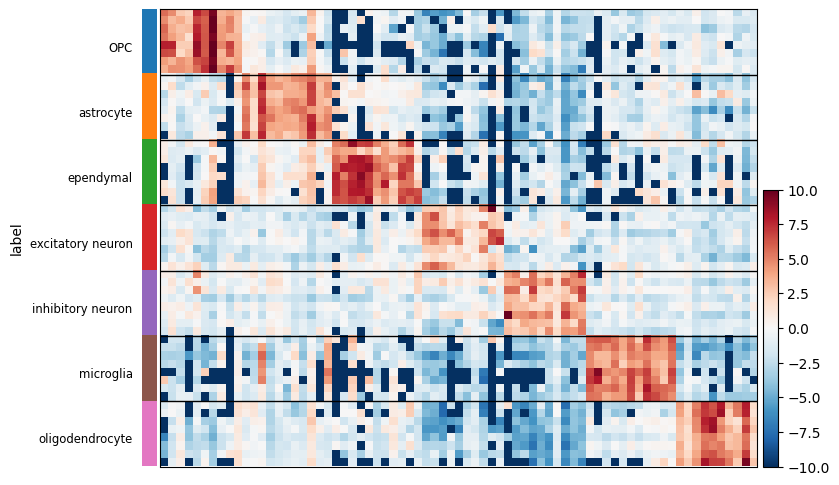

In [ ]:
import anndata as ad
new_col = []
for key in scdata.obs.celltype.unique():
    for key2 in ['BQ','YB','PC','HM','NG','QN', 'CT','XQ']:
        new_col.append(f'{key}:{key2}')

final_df = final_df.loc[:,new_col].T 
final_df.columns = gene_list 
print(final_df.shape) 

adata = ad.AnnData(final_df.values, )
adata.obs.index = final_df.index
adata.var_names = gene_list

new_label = []
for key in scdata.obs.celltype.unique():
    new_label += [key]*8
adata.obs.loc[:,'label'] = new_label

sc.tl.rank_genes_groups(adata, groupby= 'label', method = 'wilcoxon')

'''get group marker gene'''
cell_list = [ 'OPC','astrocyte','ependymal','excitatory neuron','inhibitory neuron','microglia','oligodendrocyte',]
gene_array = []
for key in cell_list:
    df =sc.get.rank_genes_groups_df(adata, [key])
    gene_array += list(df['names'][:10].values) 

    if marker_dic[key][0] not in df['names'][:10].values:
        gene_array += [marker_dic[key][0]]

sc.pl.heatmap(adata, var_names = gene_array, groupby = 'label', cmap = 'RdBu_r',vmin = -10, vmax = 10)
# sc.pl.rank_genes_groups_heatmap(adata, n_genes=10,  dendrogram=False, cmap = 'RdBu_r',vmax = 12, vmin = -10, figsize = (15,8),show_gene_labels=True, show = False)
#plt.savefig('matrix_plot_7cell.pdf', bbox_inches='tight')

## PLOT THE LOG2FC value in deg heatmap

In [29]:
map_dic = {'CY': 'eco',
           'JT': 'eco',
           'T': 'eco',
           'QF': 'neco',
           'M': 'neco'}
scdata.obs.loc[:,'eco'] = scdata.obs.species.map(map_dic)

In [31]:
## 在每一个脑区下计算 6 个细胞类型的DEG matrix plot

all_res = []
gene_list = scdata.raw.var.index
for key in scdata.obs.tissues.unique():
    adata = scdata[scdata.obs.tissues == key]
    idx = adata.obs.eco == 'eco'
    adata = adata[idx,:]
    sc.tl.rank_genes_groups(adata, 'celltype')

    tissue_res = {}

    for cell in scdata.obs.celltype.unique():
        df = sc.get.rank_genes_groups_df(adata, group = [cell])
        df.index = df['names'].values 
        df = df.loc[gene_list,:]
        tissue_res[cell] = df['logfoldchanges'].values 

    tissue_df = pd.DataFrame(tissue_res)
    new_col = [f'eco-{col}:{key}' for col in tissue_df.columns]
    tissue_df.columns = new_col
    all_res.append(tissue_df)


eco_df = pd.concat(all_res, axis = 1)
eco_df.index = gene_list


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/an

(56, 9915)


In [32]:
## 在每一个脑区下计算 6 个细胞类型的DEG matrix plot

all_res = []
gene_list = scdata.raw.var.index
for key in scdata.obs.tissues.unique():
    adata = scdata[scdata.obs.tissues == key]
    idx = adata.obs.eco == 'neco'
    adata = adata[idx,:]
    sc.tl.rank_genes_groups(adata, 'celltype')

    tissue_res = {}

    for cell in scdata.obs.celltype.unique():
        df = sc.get.rank_genes_groups_df(adata, group = [cell])
        df.index = df['names'].values 
        df = df.loc[gene_list,:]
        tissue_res[cell] = df['logfoldchanges'].values 

    tissue_df = pd.DataFrame(tissue_res)
    new_col = [f'neco-{col}:{key}' for col in tissue_df.columns]
    tissue_df.columns = new_col
    all_res.append(tissue_df)


neco_df = pd.concat(all_res, axis = 1)
neco_df.index = gene_list
print(neco_df.shape)

/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/an

(9915, 56)


In [36]:
final_df = pd.concat([eco_df, neco_df], axis = 1)
final_df.to_csv('logfc_gene.csv')

In [37]:
final_df

,eco-inhibitory neuron:BQ,eco-excitatory neuron:BQ,eco-oligodendrocyte:BQ,eco-OPC:BQ,eco-astrocyte:BQ,eco-ependymal:BQ,eco-microglia:BQ,eco-inhibitory neuron:CT,eco-excitatory neuron:CT,eco-oligodendrocyte:CT,...,neco-astrocyte:XQ,neco-ependymal:XQ,neco-microglia:XQ,neco-inhibitory neuron:YB,neco-excitatory neuron:YB,neco-oligodendrocyte:YB,neco-OPC:YB,neco-astrocyte:YB,neco-ependymal:YB,neco-microglia:YB
2610318n02rik,0.798742,-0.043488,-22.175625,-22.101389,0.064548,-22.096296,-22.088186,3.221384,-2.262303,-23.224657,...,-23.736315,-23.698273,-23.697477,-18.137419,18.198956,-18.060366,-18.029951,-18.035143,-18.030951,-18.031862
2700097o09rik,0.905828,-0.295776,-0.458770,-0.859130,-0.833505,0.165497,-1.535595,1.398758,-0.618346,-1.152314,...,-0.409241,-1.775676,-1.341038,1.408759,-1.112530,0.329106,0.980747,0.625585,-0.161652,-0.981222
A1cf,2.608466,-1.982116,-1.646678,-0.195387,0.163968,-24.287132,-24.278957,2.629904,-1.539087,-3.272218,...,2.821045,-23.387472,-23.386679,6.849368,-6.177006,-20.633041,-20.602606,-20.607801,-20.603607,-20.604517
Aadat,2.234555,-1.484046,-2.500588,0.088455,0.369595,-1.264545,0.079738,2.094811,-1.038784,-3.099549,...,0.404925,-27.663641,-27.662773,0.086866,0.531362,-28.739824,0.422364,-1.857144,-0.577063,-28.705778
Aak1,3.244506,-1.148154,-1.612821,-0.419755,-2.578614,-1.678510,-0.402561,3.180581,-0.781791,-3.492074,...,-1.073551,-0.296982,-2.701359,1.339849,-0.217215,-2.816668,-0.083143,-0.642368,-0.472983,-2.409759
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zwint,0.655165,-0.069166,0.306172,-22.695280,-22.752728,-22.690184,-22.682064,1.166372,-1.032072,-0.430991,...,-1.977134,-3.232081,-2.304508,1.409274,-0.697038,-3.138155,-27.692463,-2.174856,-1.276673,-27.694567
Zxdc,0.559806,0.055086,-0.787222,-1.395270,-0.725149,-0.080127,-2.249364,0.827599,-0.403548,-0.853415,...,-0.322006,0.391070,-1.499592,0.637542,-0.355002,-0.608500,-0.509956,0.104989,0.509534,0.306365
Zyg11a,1.152061,-0.521527,-0.987200,-23.795864,-0.125442,-23.790747,-23.782597,0.069999,-0.555017,-0.686231,...,-1.582066,-24.303608,-24.302811,2.449128,-2.354764,1.157686,-23.362844,-23.368063,3.812955,-23.364765
Zyg11b,1.879117,-0.503202,-1.880203,-0.624193,-1.148815,-2.116129,-3.110843,1.648395,-0.957613,-1.653115,...,-1.347917,-1.037651,-2.214975,1.580149,-0.663338,-1.792012,-1.504273,-1.565706,-0.007680,-2.733315


(112, 9915)


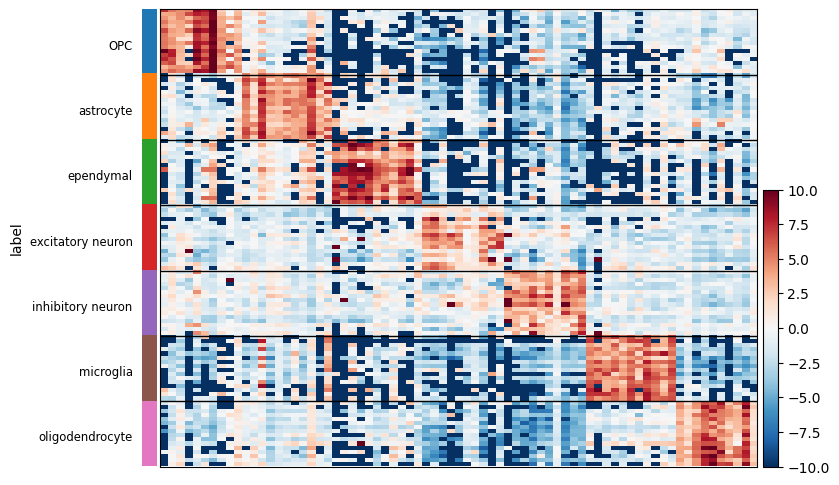

In [ ]:

import anndata as ad
new_col = []
for key in scdata.obs.celltype.unique():
    for key2 in ['BQ','YB','PC','HM','NG','QN', 'CT','XQ']:
        new_col.append(f'eco-{key}:{key2}')
        new_col.append(f'neco-{key}:{key2}')

final_df = final_df.loc[:,new_col].T 
final_df.columns = gene_list 
print(final_df.shape) 

adata = ad.AnnData(final_df.values, )
adata.obs.index = final_df.index
adata.var_names = gene_list

new_label = []
for key in scdata.obs.celltype.unique():
    new_label += [key]*16
adata.obs.loc[:,'label'] = new_label
sc.pl.heatmap(adata, var_names = gene_array, groupby = 'label', cmap = 'RdBu_r',vmin = -10, vmax = 10)
# sc.pl.rank_genes_groups_heatmap(adata, n_genes=10,  dendrogram=False, cmap = 'RdBu_r',vmax = 12, vmin = -10, figsize = (15,8),show_gene_labels=True, show = False)
#plt.savefig('matrix_plot_7cell.pdf', bbox_inches='tight')


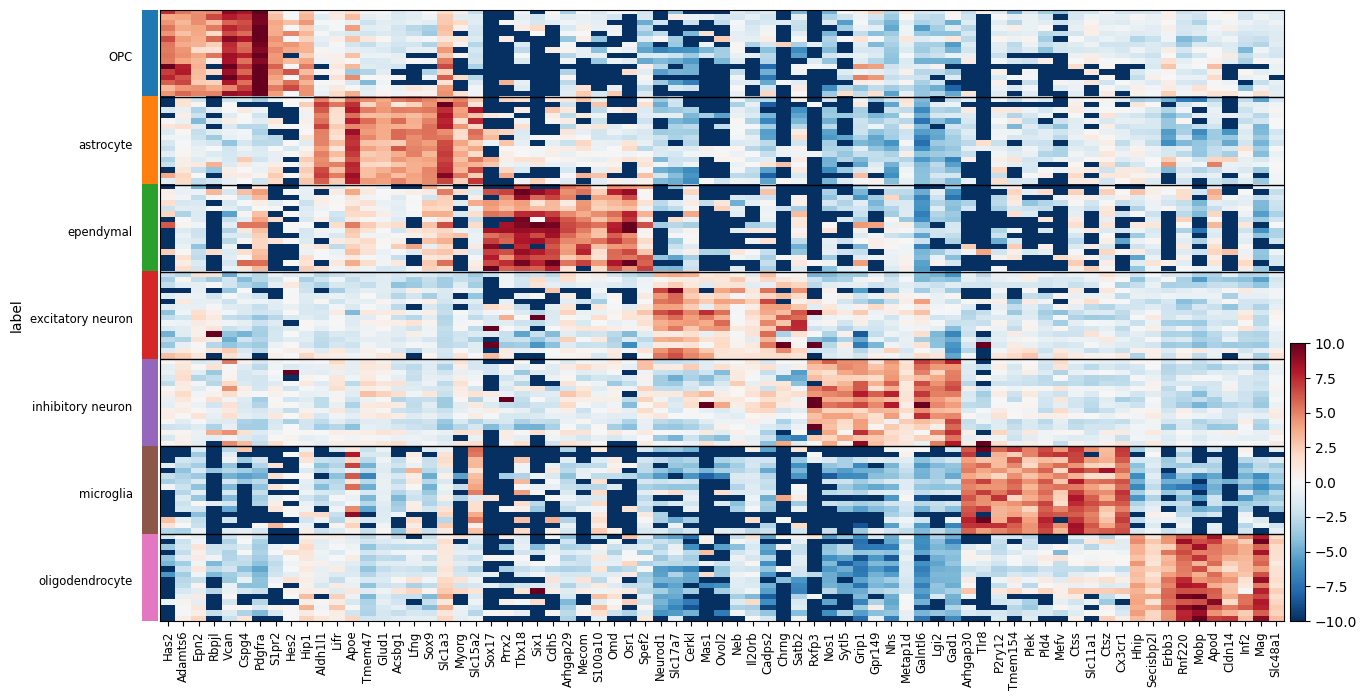

In [42]:
sc.pl.heatmap(adata, var_names = gene_array, groupby = 'label', cmap = 'RdBu_r',vmin = -10, vmax = 10, show = False, figsize=(15,8), show_gene_labels=True)
plt.savefig('heatmap.pdf', bbox_inches='tight', dpi = 600)

In [44]:
final_df.to_csv('gene_logfc.csv')


In [45]:
with open('gene.txt', 'w') as f:
    for ele in gene_array:
        f.write(ele + '\n')